In [ ]:
# !pip install ucimlrepo tensorflow   # descomente se necessário
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
pd.set_option("display.float_format", "{:.4f}".format)

In [ ]:
bean = fetch_ucirepo(id=602)
df = bean.data.original.copy()
print(df.shape)
df['Class'].value_counts()

In [ ]:
df['Class'].value_counts(normalize=True).round(3)

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

In [ ]:
# Transformação da classe em coluna numérica
df['rotulo'] = df['Class'].astype('category').cat.codes
classes = dict(df[['rotulo', 'Class']].drop_duplicates().sort_values('rotulo').values)
print(classes)

df_encoded = df.drop('Class', axis=1)
df_encoded.describe().T

Class
DERMASON    0.261
SIRA        0.194
SEKER       0.149
HOROZ       0.142
CALI        0.120
BARBUNYA    0.097
BOMBAY      0.038
Name: proportion, dtype: float64

In [ ]:
print("Linhas duplicadas:", df_encoded.duplicated().sum())
# Remoção das duplicadas (atribuindo o resultado e descartando o índice antigo)
df_encoded = df_encoded.drop_duplicates().reset_index(drop=True)
print("Shape após remoção:", df_encoded.shape)

feats = df_encoded.columns.drop('rotulo')
X = df_encoded[feats].values.astype('float32')
Y = df_encoded['rotulo'].values
n_features, n_classes = X.shape[1], len(classes)
print(f"{n_features} atributos, {n_classes} classes")

{np.int8(5): 'SEKER', np.int8(0): 'BARBUNYA', np.int8(1): 'BOMBAY', np.int8(2): 'CALI', np.int8(4): 'HOROZ', np.int8(6): 'SIRA', np.int8(3): 'DERMASON'}


In [ ]:
SPLIT_SEED = 42
X_trainfull, X_test, y_trainfull, y_test = train_test_split(
    X, Y, test_size=0.20, stratify=Y, random_state=SPLIT_SEED)   # X_test/y_test NÃO serão usados aqui

X_tr, X_val, y_tr, y_val = train_test_split(
    X_trainfull, y_trainfull, test_size=0.15, stratify=y_trainfull, random_state=SPLIT_SEED)

scaler = StandardScaler().fit(X_tr)
X_tr_s, X_val_s = scaler.transform(X_tr), scaler.transform(X_val)

# One-hot para a Entropia Cruzada Categórica
Y_tr  = keras.utils.to_categorical(y_tr,  n_classes)
Y_val = keras.utils.to_categorical(y_val, n_classes)

print(f"Treino: {X_tr_s.shape} | Validação: {X_val_s.shape} | Teste (reservado): {X_test.shape}")

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


In [ ]:
CONFIG = dict(
    hidden_units=[64, 32],
    hidden_activation='relu',
    output_activation='softmax',
    learning_rate=0.01,
    momentum=0.0,
    epochs=100,
    batch_size=32,
)
SEEDS = [0, 1, 2, 3, 4]   # uma semente por treinamento -> 5 inicializações diferentes


def build_mlp(seed, cfg=CONFIG):
    """MLP com pesos inicializados a partir da semente informada."""
    model = keras.Sequential([keras.Input(shape=(n_features,))])
    for i, units in enumerate(cfg['hidden_units']):
        model.add(layers.Dense(units, activation=cfg['hidden_activation'],
                               kernel_initializer=keras.initializers.HeNormal(seed=seed + i),
                               name=f'oculta_{i+1}'))
    model.add(layers.Dense(n_classes, activation=cfg['output_activation'],
                           kernel_initializer=keras.initializers.GlorotUniform(seed=seed + 100),
                           name='saida'))
    model.compile(
        optimizer=keras.optimizers.SGD(learning_rate=cfg['learning_rate'], momentum=cfg['momentum']),
        loss=keras.losses.CategoricalCrossentropy(),
        metrics=['accuracy'])
    return model

build_mlp(0).summary()

np.int64(68)

In [8]:
def reset_seeds(seed):
    """Reinicia todos os geradores de números aleatórios (Python, NumPy, TensorFlow)."""
    keras.backend.clear_session()
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)

histories, init_weights, models, rows = {}, {}, {}, []

for seed in SEEDS:
    reset_seeds(seed)
    model = build_mlp(seed)
    init_weights[seed] = model.get_layer('oculta_1').get_weights()[0].ravel().copy()
    loss0, acc0 = model.evaluate(X_tr_s, Y_tr, verbose=0)          # antes de treinar

    h = model.fit(X_tr_s, Y_tr, validation_data=(X_val_s, Y_val),
                  epochs=CONFIG['epochs'], batch_size=CONFIG['batch_size'],
                  shuffle=True, verbose=0)
    hist = pd.DataFrame(h.history); hist.index += 1
    histories[seed], models[seed] = hist, model

    acc_tr = hist['accuracy']
    rows.append({
        'Semente': seed,
        'Perda inicial': loss0,
        'Acurácia inicial': acc0,
        'Perda final (treino)': hist['loss'].iloc[-1],
        'Acurácia final (treino)': acc_tr.iloc[-1],
        'Perda final (val)': hist['val_loss'].iloc[-1],
        'Acurácia final (val)': hist['val_accuracy'].iloc[-1],
        'Época p/ 90% (treino)': int(acc_tr.ge(0.90).idxmax()) if acc_tr.ge(0.90).any() else np.nan,
        'Melhor época (val_loss)': int(hist['val_loss'].idxmin()),
    })
    print(f"Semente {seed}: perda={hist['loss'].iloc[-1]:.4f}  acc={acc_tr.iloc[-1]:.4f}  "
          f"| val_perda={hist['val_loss'].iloc[-1]:.4f}  val_acc={hist['val_accuracy'].iloc[-1]:.4f}")

resultados = pd.DataFrame(rows).set_index('Semente')

Semente 0: perda=0.1730  acc=0.9359  | val_perda=0.1602  val_acc=0.9453
Semente 1: perda=0.1754  acc=0.9359  | val_perda=0.1627  val_acc=0.9477
Semente 2: perda=0.1771  acc=0.9339  | val_perda=0.1637  val_acc=0.9397
Semente 3: perda=0.1736  acc=0.9353  | val_perda=0.1620  val_acc=0.9440
Semente 4: perda=0.1712  acc=0.9356  | val_perda=0.1673  val_acc=0.9471


In [9]:
resumo = resultados.agg(['mean', 'std', 'min', 'max'])
resumo.index = ['Média', 'Desvio padrão', 'Mínimo', 'Máximo']
display(resultados)
display(resumo)

,Perda inicial,Acurácia inicial,Perda final (treino),Acurácia final (treino),Perda final (val),Acurácia final (val),Época p/ 90% (treino),Melhor época (val_loss)
Semente,,,,,,,,
0,2.298917,0.130756,0.172980,0.935925,0.160222,0.945264,3,100
1,2.705304,0.078301,0.175424,0.935925,0.162720,0.947724,4,100
2,3.656591,0.144331,0.177083,0.933862,0.163662,0.939729,4,99
3,2.002952,0.173436,0.173559,0.935274,0.162039,0.944034,4,95
4,2.905178,0.096329,0.171194,0.935600,0.167279,0.947109,3,76


,Perda inicial,Acurácia inicial,Perda final (treino),Acurácia final (treino),Perda final (val),Acurácia final (val),Época p/ 90% (treino),Melhor época (val_loss)
Média,2.713788,0.124631,0.174048,0.935317,0.163184,0.944772,3.600000,94.000000
Desvio padrão,0.633045,0.037931,0.002271,0.000857,0.002612,0.003178,0.547723,10.271319
Mínimo,2.002952,0.078301,0.171194,0.933862,0.160222,0.939729,3.000000,76.000000
Máximo,3.656591,0.173436,0.177083,0.935925,0.167279,0.947724,4.000000,100.000000


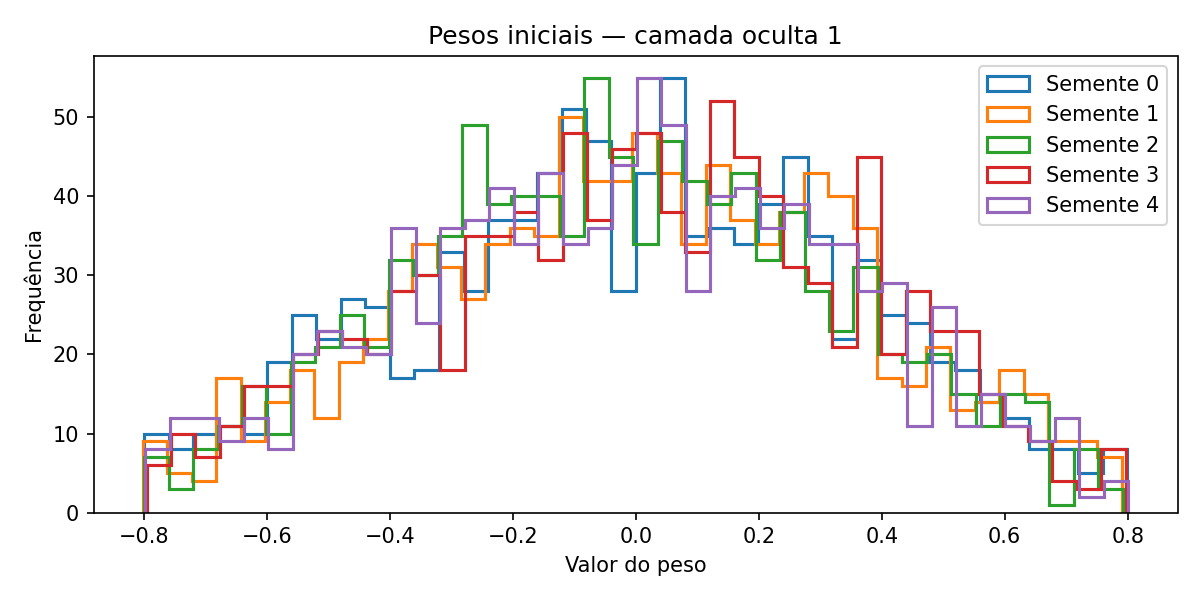

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for seed in SEEDS:
    ax.hist(init_weights[seed], bins=40, histtype='step', linewidth=1.5, label=f'Semente {seed}')
ax.set(title='Pesos iniciais — camada oculta 1', xlabel='valor do peso', ylabel='frequência')
ax.legend(); plt.tight_layout(); plt.show()

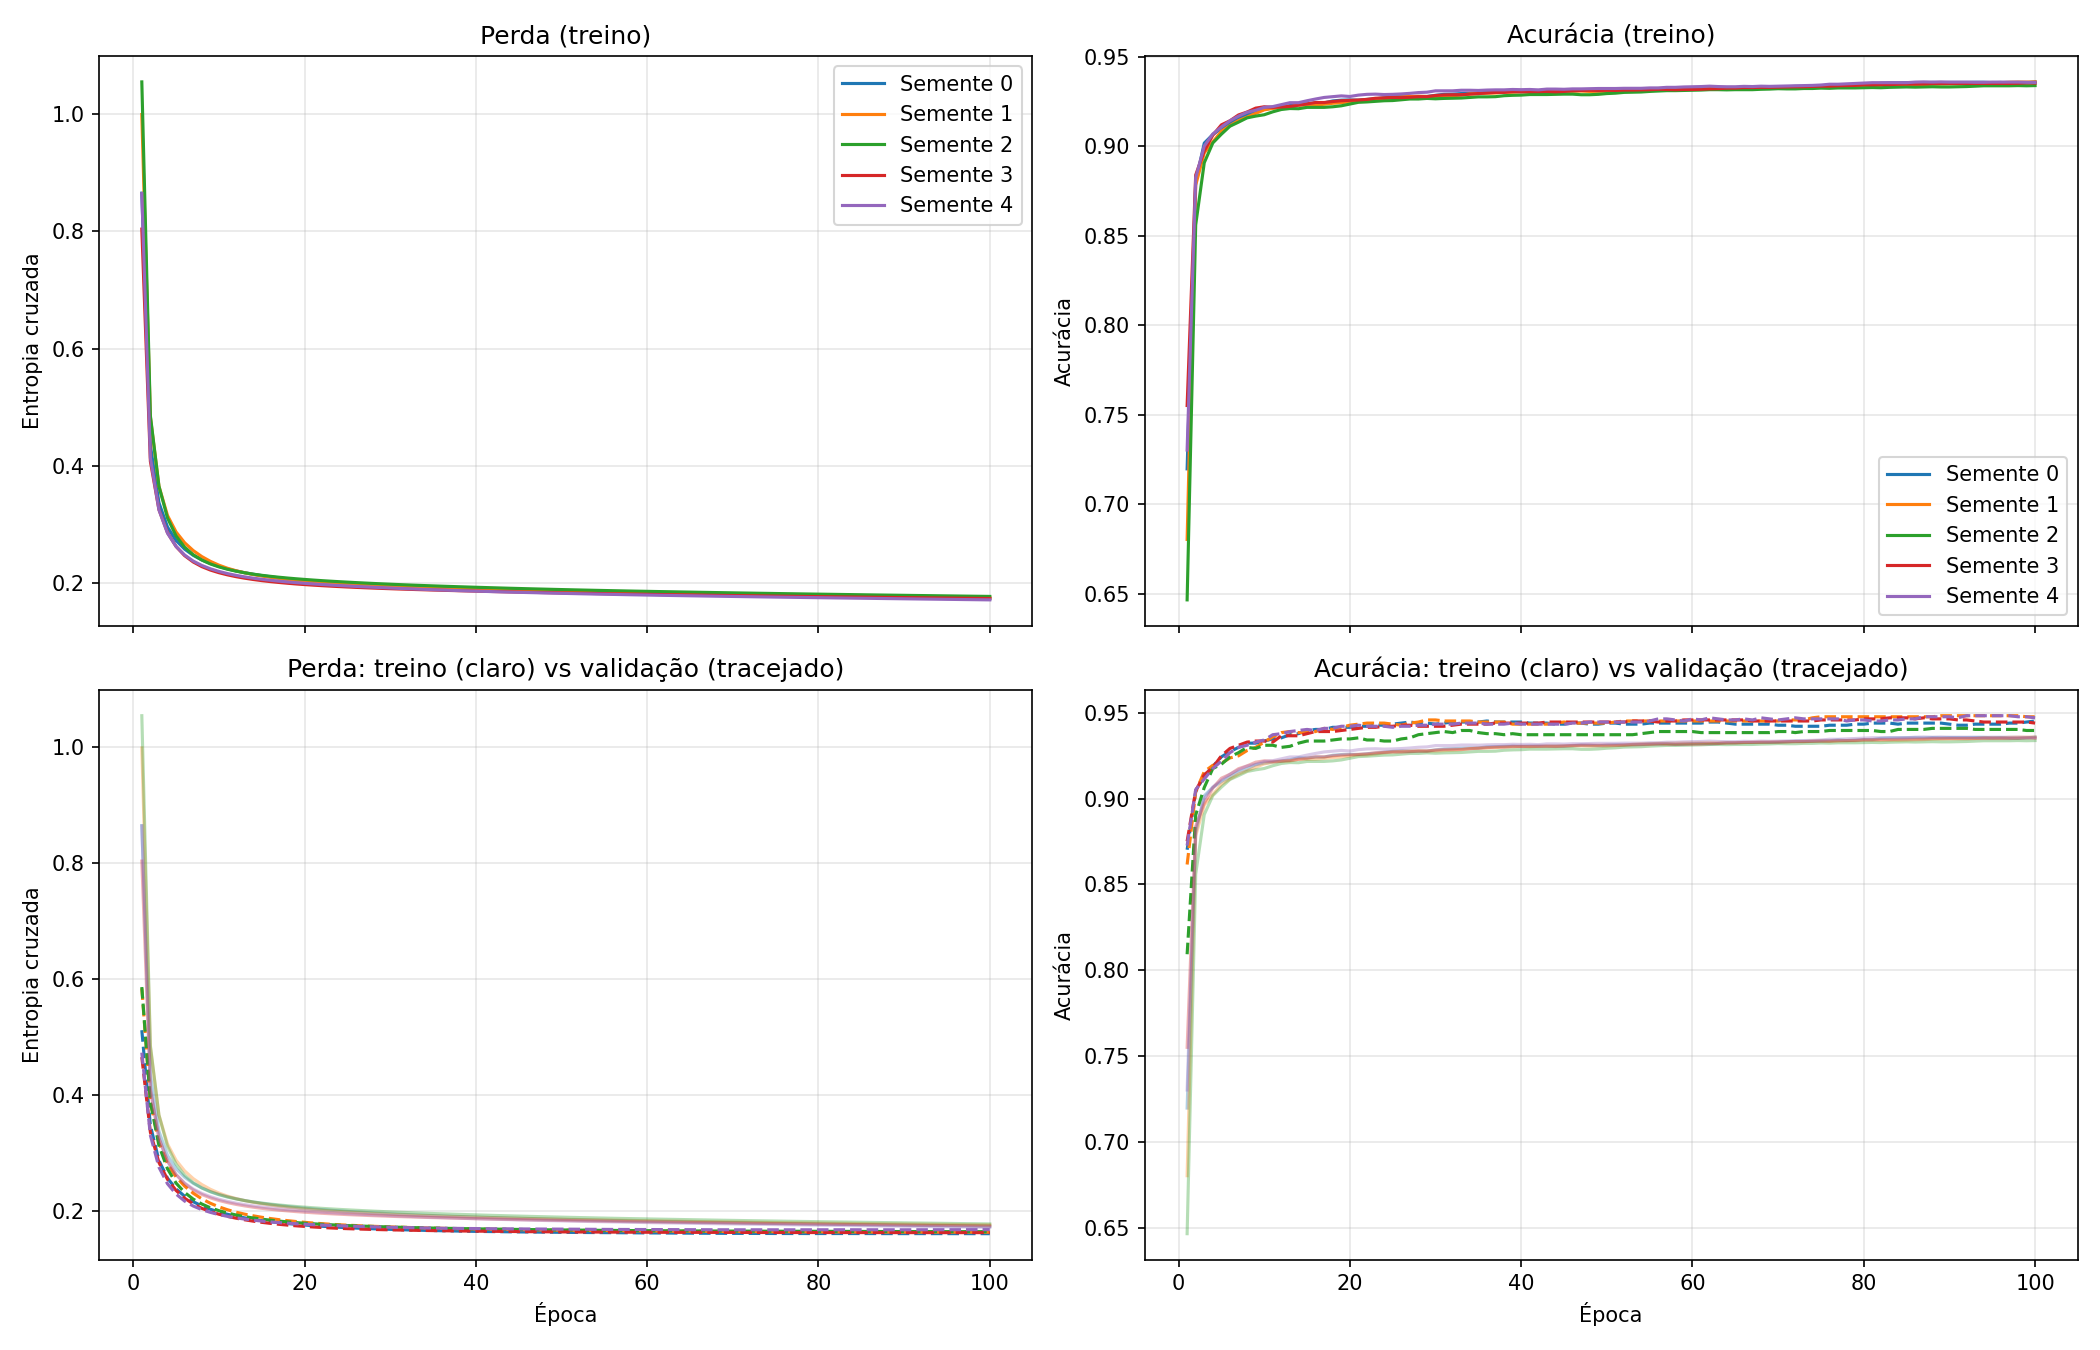

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
cores = plt.cm.tab10.colors
for k, seed in enumerate(SEEDS):
    h = histories[seed]
    axes[0, 0].plot(h['loss'], color=cores[k], label=f'Semente {seed}')
    axes[0, 1].plot(h['accuracy'], color=cores[k], label=f'Semente {seed}')
    axes[1, 0].plot(h['loss'], color=cores[k], alpha=.35)
    axes[1, 0].plot(h['val_loss'], color=cores[k], linestyle='--')
    axes[1, 1].plot(h['accuracy'], color=cores[k], alpha=.35)
    axes[1, 1].plot(h['val_accuracy'], color=cores[k], linestyle='--')

axes[0, 0].set(title='Perda (treino)', ylabel='Entropia cruzada')
axes[0, 1].set(title='Acurácia (treino)', ylabel='Acurácia')
axes[1, 0].set(title='Perda: treino (claro) vs validação (tracejado)', xlabel='Época', ylabel='Entropia cruzada')
axes[1, 1].set(title='Acurácia: treino (claro) vs validação (tracejado)', xlabel='Época', ylabel='Acurácia')
for ax in axes.ravel(): ax.grid(alpha=.3)
axes[0, 0].legend(); axes[0, 1].legend(loc='lower right')
plt.tight_layout(); plt.show()

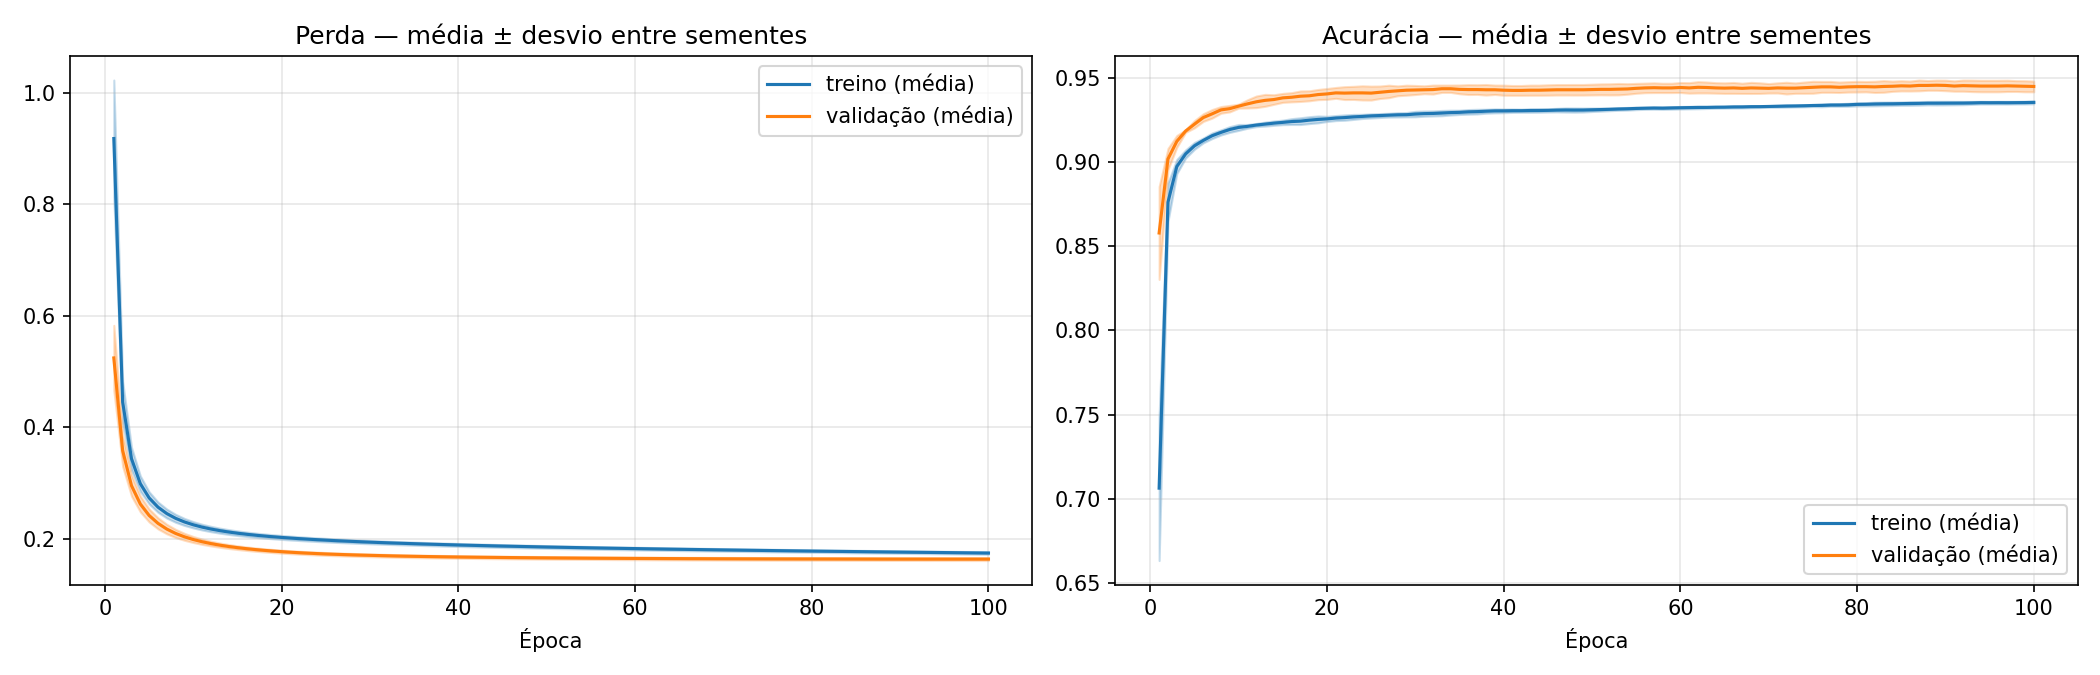

In [12]:
# Média ± desvio padrão entre as 5 inicializações
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, met, titulo in [(axes[0], 'loss', 'Perda'), (axes[1], 'accuracy', 'Acurácia')]:
    for suf, cor, nome in [('', 'tab:blue', 'treino'), ('val_', 'tab:orange', 'validação')]:
        M = pd.concat([histories[s][suf + met] for s in SEEDS], axis=1)
        m, sd = M.mean(axis=1), M.std(axis=1)
        ax.plot(m, color=cor, label=f'{nome} (média)')
        ax.fill_between(m.index, m - sd, m + sd, color=cor, alpha=.25)
    ax.set(title=f'{titulo} — média ± desvio entre sementes', xlabel='Época'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

Semente 4

              precision    recall  f1-score   support

    BARBUNYA      0.961     0.928     0.944       898
      BOMBAY      1.000     1.000     1.000       355
        CALI      0.940     0.960     0.950      1108
    DERMASON      0.912     0.949     0.930      2411
       HOROZ      0.966     0.953     0.959      1265
       SEKER      0.957     0.961     0.959      1378
        SIRA      0.904     0.864     0.884      1793

    accuracy                          0.936      9208
   macro avg      0.948     0.945     0.947      9208
weighted avg      0.936     0.936     0.936      9208



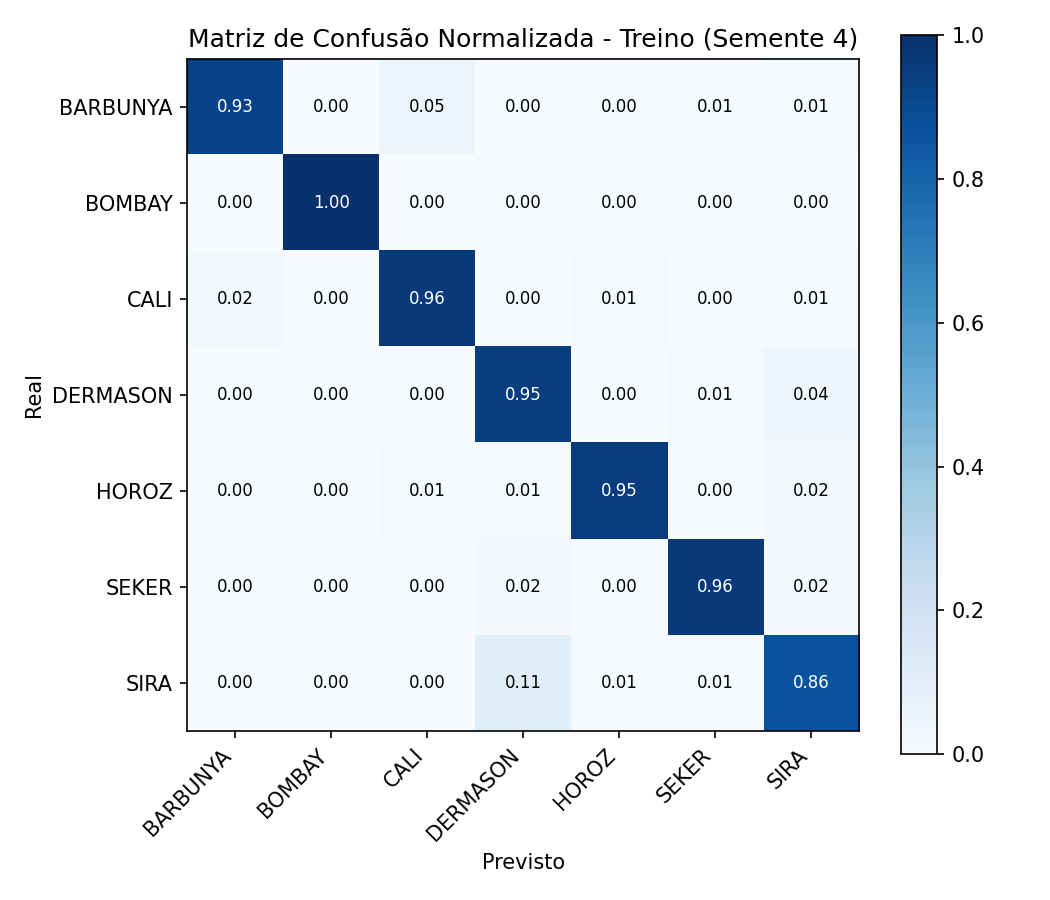

In [13]:
melhor = resultados['Perda final (treino)'].idxmin()
pred = models[melhor].predict(X_tr_s, verbose=0).argmax(axis=1)
nomes = [classes[i] for i in range(n_classes)]
print(f"Semente {melhor}\n")
print(classification_report(y_tr, pred, target_names=nomes, digits=3))

cm = confusion_matrix(y_tr, pred, normalize='true')
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(n_classes), nomes, rotation=45, ha='right'); ax.set_yticks(range(n_classes), nomes)
for i in range(n_classes):
    for j in range(n_classes):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > .5 else 'black', fontsize=8)
ax.set(xlabel='Previsto', ylabel='Real', title='Matriz de confusão normalizada (treino)')
plt.colorbar(im); plt.tight_layout(); plt.show()

In [14]:
r, s = resultados, resumo
acc_tr, acc_val = r['Acurácia final (treino)'], r['Acurácia final (val)']
loss_tr, loss_val = r['Perda final (treino)'], r['Perda final (val)']
gap = (acc_tr - acc_val).mean()
gap_loss = (loss_val - loss_tr).mean()
cv_loss = loss_tr.std() / loss_tr.mean() * 100
amp_acc = (acc_tr.max() - acc_tr.min()) * 100
ep90 = r['Época p/ 90% (treino)']
best_ep = r['Melhor época (val_loss)']

# Diagnóstico de over/underfitting
if acc_tr.mean() < 0.85:
    diag = ("a acurácia de treino ainda é relativamente baixa, o que sugere **underfitting** — o modelo pode precisar de "
            "mais épocas, maior taxa de aprendizado ou mais capacidade.")
elif gap > 0.03 or gap_loss > 0.05:
    diag = (f"há uma diferença perceptível entre treino e validação (acurácia {gap*100:.2f} p.p. maior no treino), "
            "indicando **início de overfitting**; regularização ou parada antecipada seriam recomendáveis.")
else:
    diag = (f"treino e validação permanecem próximos (diferença média de {gap*100:.2f} p.p. na acurácia e "
            f"{gap_loss:+.4f} na perda), **sem indícios relevantes de overfitting**; como a acurácia de treino é alta, "
            "também **não há underfitting**.")

if best_ep.mean() < CONFIG['epochs'] * 0.8:
    obs_ep = (f"A menor perda de validação ocorreu, em média, na época {best_ep.mean():.0f}; depois disso a validação "
              "estabiliza ou piora levemente, sinal de que o ganho adicional vem principalmente do ajuste ao treino.")
else:
    obs_ep = (f"A perda de validação ainda caía nas últimas épocas (melhor época média: {best_ep.mean():.0f}), "
              "o que indica que o modelo não saturou e poderia se beneficiar de mais épocas.")

rec = pd.Series(np.diag(cm), index=nomes).sort_values()
piores = ', '.join(f"{c} ({v*100:.1f}%)" for c, v in rec.head(3).items())
melhor_cls = f"{rec.index[-1]} ({rec.iloc[-1]*100:.1f}%)"
sens = "baixa" if cv_loss < 5 and amp_acc < 1 else ("moderada" if cv_loss < 15 and amp_acc < 3 else "alta")

display(Markdown(f'''
**Resumo numérico (5 inicializações)**

| Métrica | Média ± desvio | Mín – Máx |
|---|---|---|
| Perda final (treino) | {loss_tr.mean():.4f} ± {loss_tr.std():.4f} | {loss_tr.min():.4f} – {loss_tr.max():.4f} |
| Acurácia final (treino) | {acc_tr.mean():.4f} ± {acc_tr.std():.4f} | {acc_tr.min():.4f} – {acc_tr.max():.4f} |
| Perda final (validação) | {loss_val.mean():.4f} ± {loss_val.std():.4f} | {loss_val.min():.4f} – {loss_val.max():.4f} |
| Acurácia final (validação) | {acc_val.mean():.4f} ± {acc_val.std():.4f} | {acc_val.min():.4f} – {acc_val.max():.4f} |
| Perda inicial (antes do treino) | {r['Perda inicial'].mean():.4f} ± {r['Perda inicial'].std():.4f} | {r['Perda inicial'].min():.4f} – {r['Perda inicial'].max():.4f} |
| Época em que atinge 90% (treino) | {ep90.mean():.1f} ± {ep90.std():.1f} | {ep90.min():.0f} – {ep90.max():.0f} |

### c. Análise e discussão
- **Comparação entre os treinamentos:** as cinco execuções partem de perdas iniciais diferentes
  ({r['Perda inicial'].min():.3f} a {r['Perda inicial'].max():.3f}; o valor de referência para palpite aleatório é
  ln(7) ≈ {np.log(n_classes):.3f}), mas convergem para perdas finais de {loss_tr.min():.4f} a {loss_tr.max():.4f}.
  A acurácia de 90% no treino é atingida entre as épocas {ep90.min():.0f} e {ep90.max():.0f}, ou seja, a inicialização
  afeta sobretudo a **velocidade inicial** de convergência, e pouco o ponto final.
- **Estabilidade e desempenho:** coeficiente de variação da perda final = {cv_loss:.2f}% e amplitude da acurácia final
  de treino = {amp_acc:.2f} p.p. Nenhuma execução divergiu ou ficou presa em platô.
- **Underfitting / overfitting:** {diag} {obs_ep}
- **Sensibilidade à inicialização:** **{sens}**. Com He Normal + ReLU e dados padronizados, os pontos de partida
  diferentes levam a mínimos de qualidade equivalente.
- **Comportamento geral:** a perda cai rapidamente nas primeiras épocas e depois decresce de forma lenta e suave,
  padrão esperado do SGD com taxa fixa. Pela matriz de confusão, as classes com menor recall no treino são
  {piores} — em geral variedades de formato parecido —, enquanto {melhor_cls} é a mais bem separada.

### d. Conclusão da etapa
- O modelo **foi capaz de aprender os padrões básicos** das 7 classes, com acurácia média de treino de
  {acc_tr.mean()*100:.2f}% e validação de {acc_val.mean()*100:.2f}%.
- **ReLU + Softmax** se mostraram adequadas: convergência sem saturação e saídas probabilísticas coerentes com a
  entropia cruzada categórica.
- O treinamento é **estável** frente à inicialização dos pesos (variação {sens}), de modo que a topologia
  16-64-32-7 fica validada como base para a **Questão 2** (efeito da taxa de aprendizado e do momento).
'''))

**Resumo numérico (5 inicializações)**

| Métrica | Média ± desvio | Mín – Máx |
|---|---|---|
| Perda final (treino) | 0.1740 ± 0.0023 | 0.1712 – 0.1771 |
| Acurácia final (treino) | 0.9353 ± 0.0009 | 0.9339 – 0.9359 |
| Perda final (validação) | 0.1632 ± 0.0026 | 0.1602 – 0.1673 |
| Acurácia final (validação) | 0.9448 ± 0.0032 | 0.9397 – 0.9477 |
| Perda inicial (antes do treino) | 2.7138 ± 0.6330 | 2.0030 – 3.6566 |
| Época em que atinge 90% (treino) | 3.6 ± 0.5 | 3 – 4 |

### c. Análise e discussão
- **Comparação entre os treinamentos:** as cinco execuções partem de perdas iniciais diferentes
  (2.003 a 3.657; o valor de referência para palpite aleatório é
  ln(7) ≈ 1.946), mas convergem para perdas finais de 0.1712 a 0.1771.
  A acurácia de 90% no treino é atingida entre as épocas 3 e 4, ou seja, a inicialização
  afeta sobretudo a **velocidade inicial** de convergência, e pouco o ponto final.
- **Estabilidade e desempenho:** coeficiente de variação da perda final = 1.30% e amplitude da acurácia final
  de treino = 0.21 p.p. Nenhuma execução divergiu ou ficou presa em platô.
- **Underfitting / overfitting:** treino e validação permanecem próximos (diferença média de -0.95 p.p. na acurácia e -0.0109 na perda), **sem indícios relevantes de overfitting**; como a acurácia de treino é alta, também **não há underfitting**.
- **Sensibilidade à inicialização:** **baixa**. Com He Normal + ReLU e dados padronizados, os pontos de partida
  diferentes levam a mínimos de qualidade equivalente.
- **Comportamento geral:** a perda cai rapidamente nas primeiras épocas e depois decresce de forma lenta e suave,
  padrão esperado do SGD com taxa fixa. Pela matriz de confusão, as classes com menor recall no treino são
  SIRA (86.4%), BARBUNYA (92.8%), DERMASON (94.9%) — em geral variedades de formato parecido —, enquanto BOMBAY (100.0%) é a mais bem separada.

### d. Conclusão da etapa
- O modelo **foi capaz de aprender os padrões básicos** das 7 classes, com acurácia média de treino de
  93.53% e validação de 94.48%.
- **ReLU + Softmax** se mostraram adequadas: convergência sem saturação e saídas probabilísticas coerentes com a
  entropia cruzada categórica.
- O treinamento é **estável** frente à inicialização dos pesos (variação baixa), de modo que a topologia
  16-64-32-7 fica validada como base para a **Questão 2** (efeito da taxa de aprendizado e do momento).


# 2. Exploração de Hiperparâmetros de Aprendizado — Taxa de Aprendizado e Termo Momento

Nesta etapa, investigamos o impacto da taxa de aprendizado ($\eta$) e do termo momento ($\alpha$) na velocidade de convergência e estabilidade do treinamento da arquitetura validada na Questão 1 (16-64-32-7 com ReLU e Softmax).
Conforme o roteiro oficial da avaliação, utilizamos a busca em grade (**Grid Search**) com critério de parada para erro de treinamento $\le 0.001$, analisando:
* **Taxas de aprendizado:** $\eta \in [0.001, 0.01, 0.1, 0.5]$
* **Termos momento:** $\alpha \in [0.0, 0.5, 0.7, 0.9]$ (incluindo $\alpha=0.0$ como baseline de SGD puro)
* **Critério de parada:** $\text{loss} \le 0.001$ ou limite de 80 épocas.
* **Otimizador:** SGD com momento clássico e lote de tamanho 32.


In [15]:
GRID_LRS = [0.001, 0.01, 0.1, 0.5]
GRID_MOMENTUMS = [0.0, 0.5, 0.7, 0.9]
STOP_LOSS_THRESHOLD = 0.001
MAX_EPOCHS_Q2 = 80
Q2_SEED = 42

class EarlyStoppingLossThreshold(keras.callbacks.Callback):
    """Interrompe o treinamento quando a perda atinge ou fica abaixo do limiar especificado."""
    def __init__(self, threshold=0.001):
        super().__init__()
        self.threshold = threshold
        self.converged_epoch = None

    def on_epoch_end(self, epoch, logs=None):
        loss = logs.get('loss')
        if loss is not None and loss <= self.threshold:
            self.converged_epoch = epoch + 1
            self.model.stop_training = True

def build_q2_model(lr, momentum, seed=Q2_SEED):
    """Constrói a MLP com a topologia validada na Questão 1 e pesos reiniciados."""
    reset_seeds(seed)
    model = keras.Sequential([keras.Input(shape=(n_features,))])
    for i, units in enumerate(CONFIG['hidden_units']):
        model.add(layers.Dense(units, activation=CONFIG['hidden_activation'],
                               kernel_initializer=keras.initializers.HeNormal(seed=seed + i),
                               name=f'oculta_{i+1}'))
    model.add(layers.Dense(n_classes, activation=CONFIG['output_activation'],
                           kernel_initializer=keras.initializers.GlorotUniform(seed=seed + 100),
                           name='saida'))
    opt = keras.optimizers.SGD(learning_rate=lr, momentum=momentum)
    model.compile(optimizer=opt,
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=['accuracy'],
                  steps_per_execution=32)
    return model

print(f"Configuração do Grid Search: {len(GRID_LRS)} taxas x {len(GRID_MOMENTUMS)} momentos = {len(GRID_LRS)*len(GRID_MOMENTUMS)} modelos")


Configuração do Grid Search: 4 taxas x 4 momentos = 16 modelos


In [16]:
grid_histories = {}
grid_rows = []

print(f"Executando Grid Search com critério de parada loss <= {STOP_LOSS_THRESHOLD}...")
for lr in GRID_LRS:
    for mom in GRID_MOMENTUMS:
        config_key = f"lr={lr}_mom={mom}"
        model = build_q2_model(lr=lr, momentum=mom, seed=Q2_SEED)
        cb_threshold = EarlyStoppingLossThreshold(threshold=STOP_LOSS_THRESHOLD)
        
        t_start = time.time()
        h = model.fit(
            X_tr_s, Y_tr,
            validation_data=(X_val_s, Y_val),
            epochs=MAX_EPOCHS_Q2,
            batch_size=CONFIG['batch_size'],
            callbacks=[cb_threshold],
            shuffle=True,
            verbose=0
        )
        t_elapsed = time.time() - t_start
        
        hist = pd.DataFrame(h.history); hist.index += 1
        grid_histories[config_key] = hist
        
        final_loss = hist['loss'].iloc[-1]
        final_acc = hist['accuracy'].iloc[-1]
        final_val_loss = hist['val_loss'].iloc[-1]
        final_val_acc = hist['val_accuracy'].iloc[-1]
        min_loss = hist['loss'].min()
        min_loss_epoch = int(hist['loss'].idxmin())
        
        conv_ep = cb_threshold.converged_epoch
        conv_str = str(conv_ep) if conv_ep is not None else f"> {MAX_EPOCHS_Q2}"
        
        diff_loss = hist['loss'].diff().dropna()
        oscillations = (diff_loss > 0.05).sum()
        if np.isnan(final_loss) or final_loss > 5.0:
            status = "Divergente"
        elif oscillations > 5 or (hist['loss'].max() - final_loss > 1.0 and final_loss > 0.5):
            status = "Instável/Oscilatório"
        elif final_acc < 0.85:
            status = "Lento/Subótimo"
        else:
            status = "Estável/Convergente"
            
        grid_rows.append({
            'Taxa (η)': lr,
            'Momento (α)': mom,
            'Perda Final (treino)': final_loss,
            'Acurácia Final (treino)': final_acc,
            'Perda Final (val)': final_val_loss,
            'Acurácia Final (val)': final_val_acc,
            'Épocas até perda <= 0.001': conv_str,
            'Melhor Época (treino)': min_loss_epoch,
            'Menor Perda (treino)': min_loss,
            'Tempo (s)': t_elapsed,
            'Status': status
        })
        print(f"[{config_key:18s}] -> Perda={final_loss:.4f} | Acc={final_acc:.4f} | Val Perda={final_val_loss:.4f} | Val Acc={final_val_acc:.4f} | Status={status}")

df_grid = pd.DataFrame(grid_rows)


Executando Grid Search com critério de parada loss <= 0.001...
[lr=0.001_mom=0.0  ] -> Perda=0.2411 | Acc=0.9168 | Val Perda=0.2149 | Val Acc=0.9348 | Status=Estável/Convergente
[lr=0.001_mom=0.5  ] -> Perda=0.2105 | Acc=0.9230 | Val Perda=0.1861 | Val Acc=0.9416 | Status=Estável/Convergente
[lr=0.001_mom=0.7  ] -> Perda=0.1967 | Acc=0.9281 | Val Perda=0.1760 | Val Acc=0.9428 | Status=Estável/Convergente
[lr=0.001_mom=0.9  ] -> Perda=0.1770 | Acc=0.9334 | Val Perda=0.1677 | Val Acc=0.9446 | Status=Estável/Convergente
[lr=0.01_mom=0.0   ] -> Perda=0.1770 | Acc=0.9336 | Val Perda=0.1675 | Val Acc=0.9459 | Status=Estável/Convergente
[lr=0.01_mom=0.5   ] -> Perda=0.1684 | Acc=0.9363 | Val Perda=0.1656 | Val Acc=0.9446 | Status=Estável/Convergente
[lr=0.01_mom=0.7   ] -> Perda=0.1631 | Acc=0.9393 | Val Perda=0.1660 | Val Acc=0.9410 | Status=Estável/Convergente
[lr=0.01_mom=0.9   ] -> Perda=0.1492 | Acc=0.9433 | Val Perda=0.1813 | Val Acc=0.9379 | Status=Estável/Convergente
[lr=0.1_mom=0.0  

In [17]:
display(Markdown('### Tabela Comparativa de Todas as Configurações (Ordenada por Perda de Validação)'))
display(df_grid.sort_values(by=['Perda Final (val)', 'Perda Final (treino)']).reset_index(drop=True))

display(Markdown('### Matriz de Perda Final de Treinamento (η vs α)'))
pivot_loss = df_grid.pivot(index='Taxa (η)', columns='Momento (α)', values='Perda Final (treino)')
display(pivot_loss)

display(Markdown('### Matriz de Acurácia Final de Validação (η vs α)'))
pivot_acc = df_grid.pivot(index='Taxa (η)', columns='Momento (α)', values='Acurácia Final (val)')
display(pivot_acc)


### Tabela Comparativa de Todas as Configurações (Ordenada por Perda de Validação)

,Taxa (η),Momento (α),Perda Final (treino),Acurácia Final (treino),Perda Final (val),Acurácia Final (val),Épocas até perda <= 0.001,Melhor Época (treino),Menor Perda (treino),Tempo (s),Status
0,0.010,0.5,0.168443,0.936251,0.165566,0.944649,> 80,80,0.168443,32.940690,Estável/Convergente
1,0.010,0.7,0.163082,0.939292,0.166023,0.940959,> 80,80,0.163082,31.480994,Estável/Convergente
2,0.010,0.0,0.176970,0.933645,0.167545,0.945879,> 80,80,0.176970,31.663777,Estável/Convergente
3,0.001,0.9,0.176958,0.933427,0.167733,0.944649,> 80,80,0.176958,31.915318,Estável/Convergente
4,0.100,0.0,0.151191,0.942550,0.175390,0.937884,> 80,80,0.151191,29.471075,Estável/Convergente
5,0.001,0.7,0.196726,0.928106,0.175991,0.942804,> 80,80,0.196726,30.821254,Estável/Convergente
6,0.010,0.9,0.149181,0.943310,0.181329,0.937884,> 80,80,0.149181,32.298435,Estável/Convergente
7,0.001,0.5,0.210500,0.923002,0.186145,0.941574,> 80,80,0.210500,31.439178,Estável/Convergente
8,0.100,0.5,0.144523,0.943853,0.209854,0.934809,> 80,79,0.144041,30.122644,Estável/Convergente
9,0.001,0.0,0.241074,0.916811,0.214933,0.934809,> 80,80,0.241074,30.777033,Estável/Convergente


### Matriz de Perda Final de Treinamento (η vs α)

Momento (α),0.0,0.5,0.7,0.9
Taxa (η),,,,
0.001,0.241074,0.210500,0.196726,0.176958
0.010,0.176970,0.168443,0.163082,0.149181
0.100,0.151191,0.144523,0.144766,0.194156
0.500,0.142964,0.217388,1.843973,1.863174


### Matriz de Acurácia Final de Validação (η vs α)

Momento (α),0.0,0.5,0.7,0.9
Taxa (η),,,,
0.001,0.934809,0.941574,0.942804,0.944649
0.010,0.945879,0.944649,0.940959,0.937884
0.100,0.937884,0.934809,0.928044,0.930504
0.500,0.927429,0.934194,0.261993,0.194342


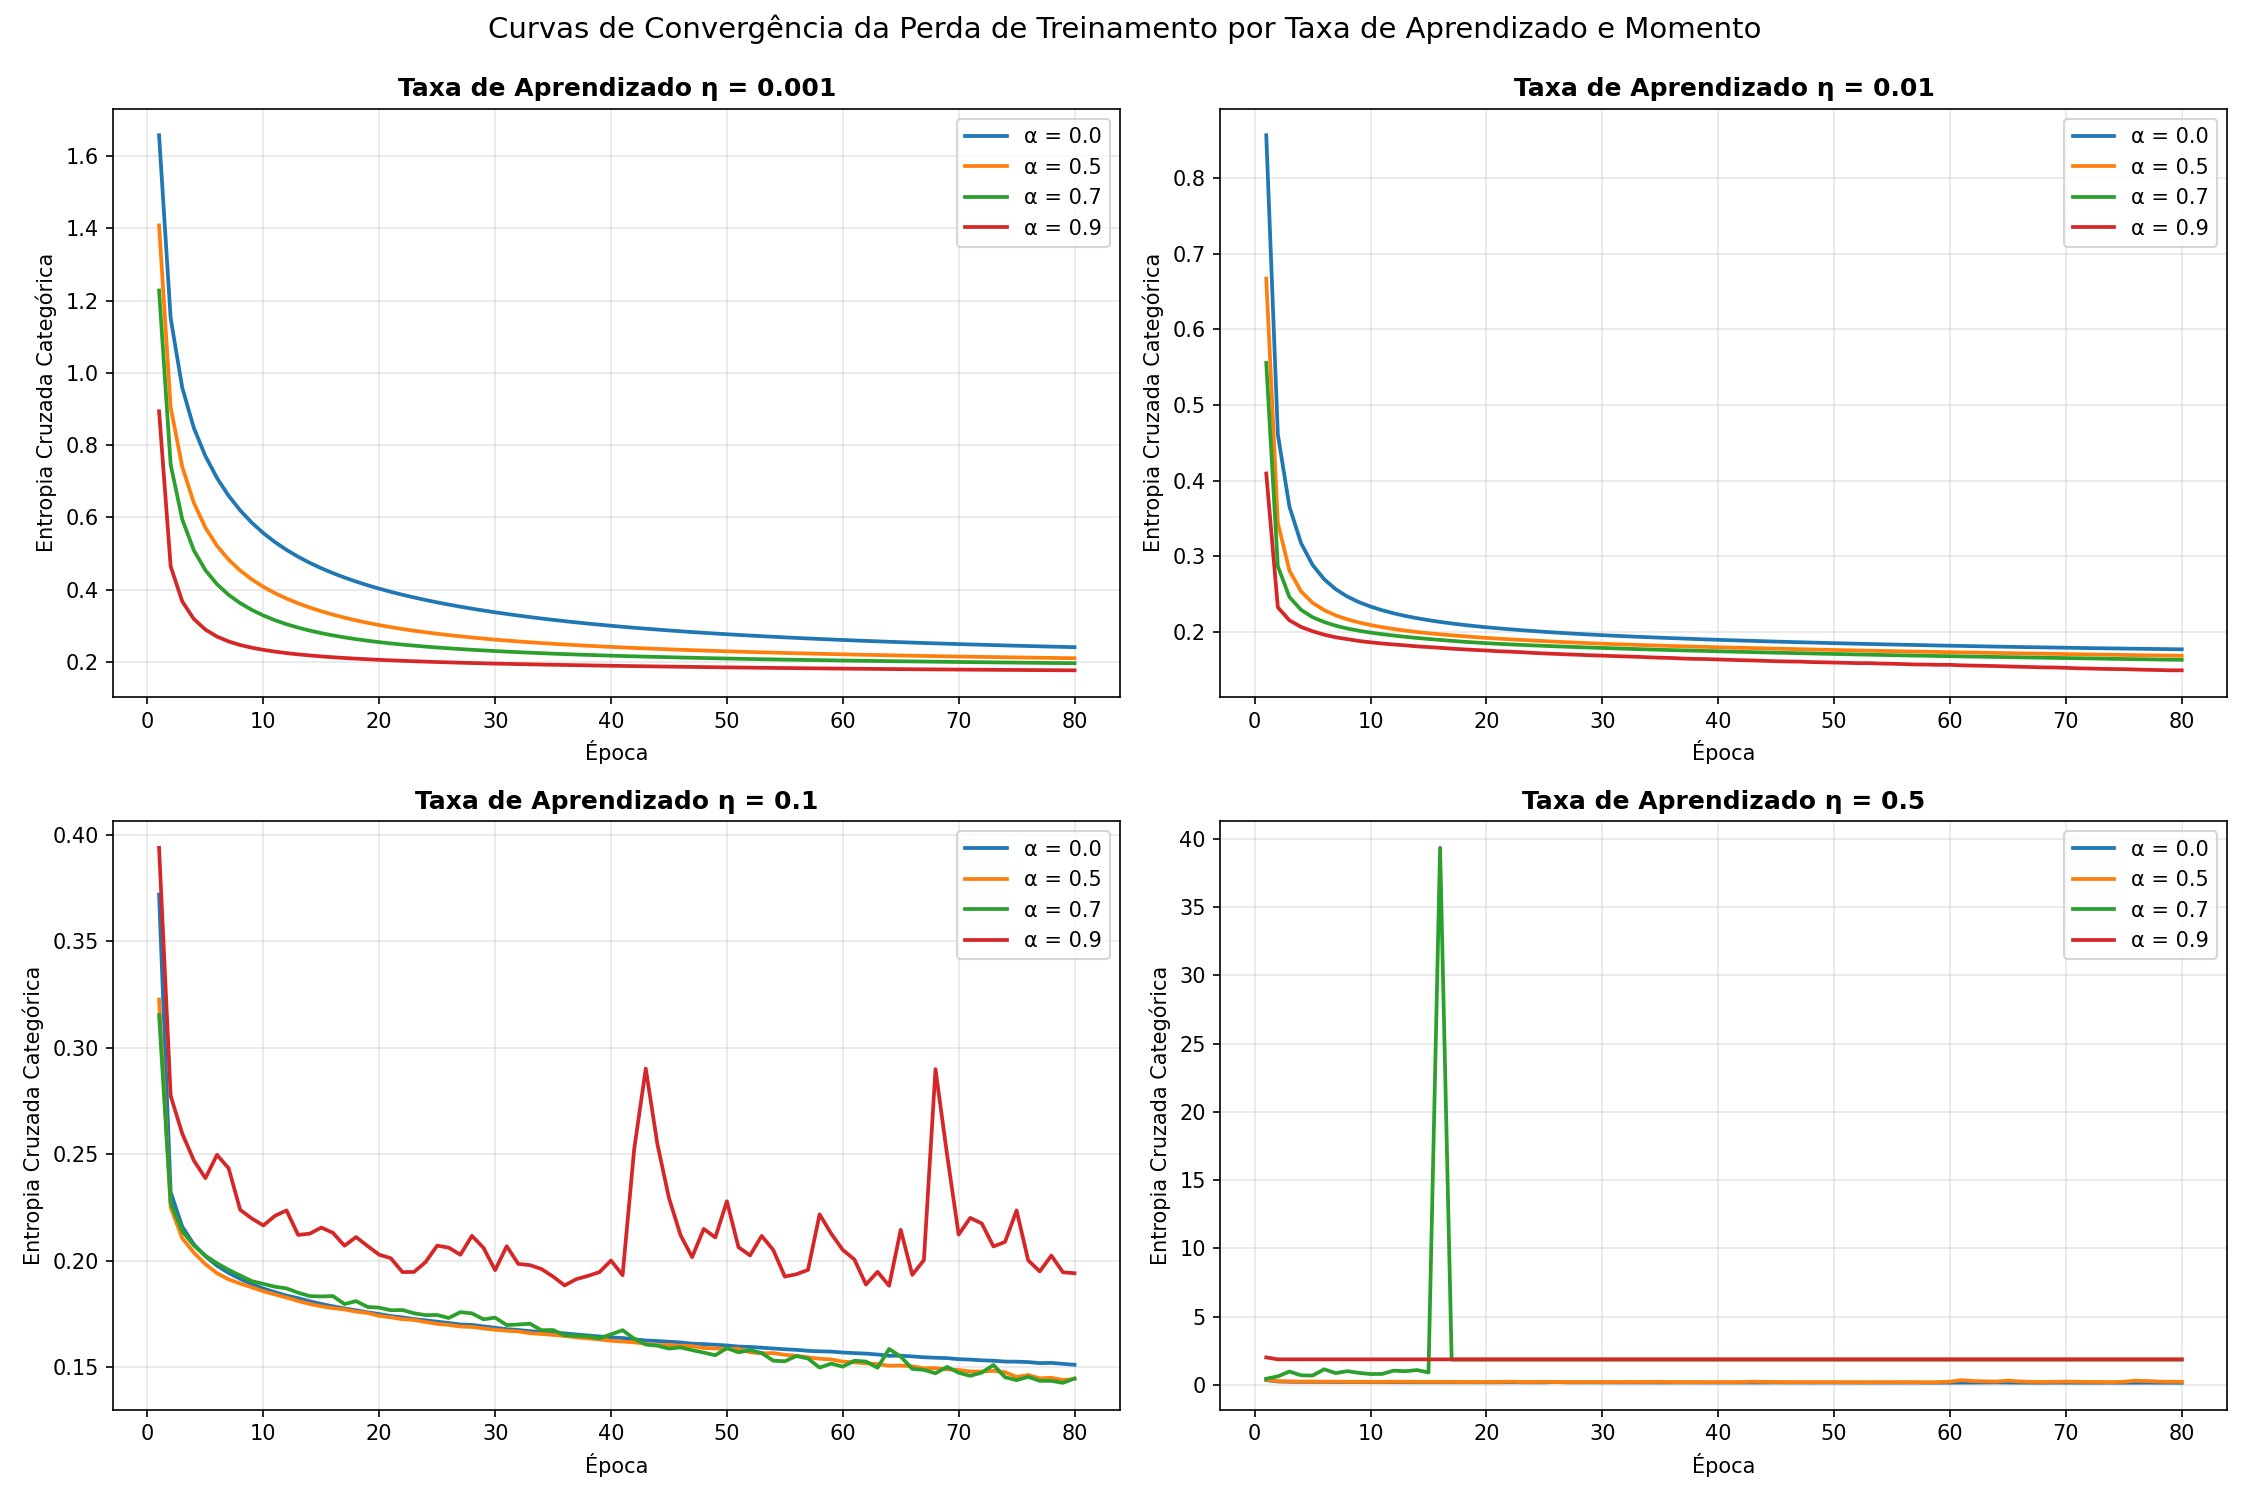

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=False)
cores_mom = {0.0: 'tab:blue', 0.5: 'tab:orange', 0.7: 'tab:green', 0.9: 'tab:red'}

for ax, lr in zip(axes.ravel(), GRID_LRS):
    for mom in GRID_MOMENTUMS:
        k = f"lr={lr}_mom={mom}"
        h = grid_histories[k]
        ax.plot(h['loss'], label=f"α = {mom}", color=cores_mom[mom], linewidth=1.8)
    ax.set_title(f"Taxa de Aprendizado η = {lr}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Época")
    ax.set_ylabel("Entropia Cruzada Categórica")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Curvas de Convergência da Perda de Treinamento por Taxa de Aprendizado e Momento", fontsize=14, y=0.99)
plt.tight_layout()
plt.show()


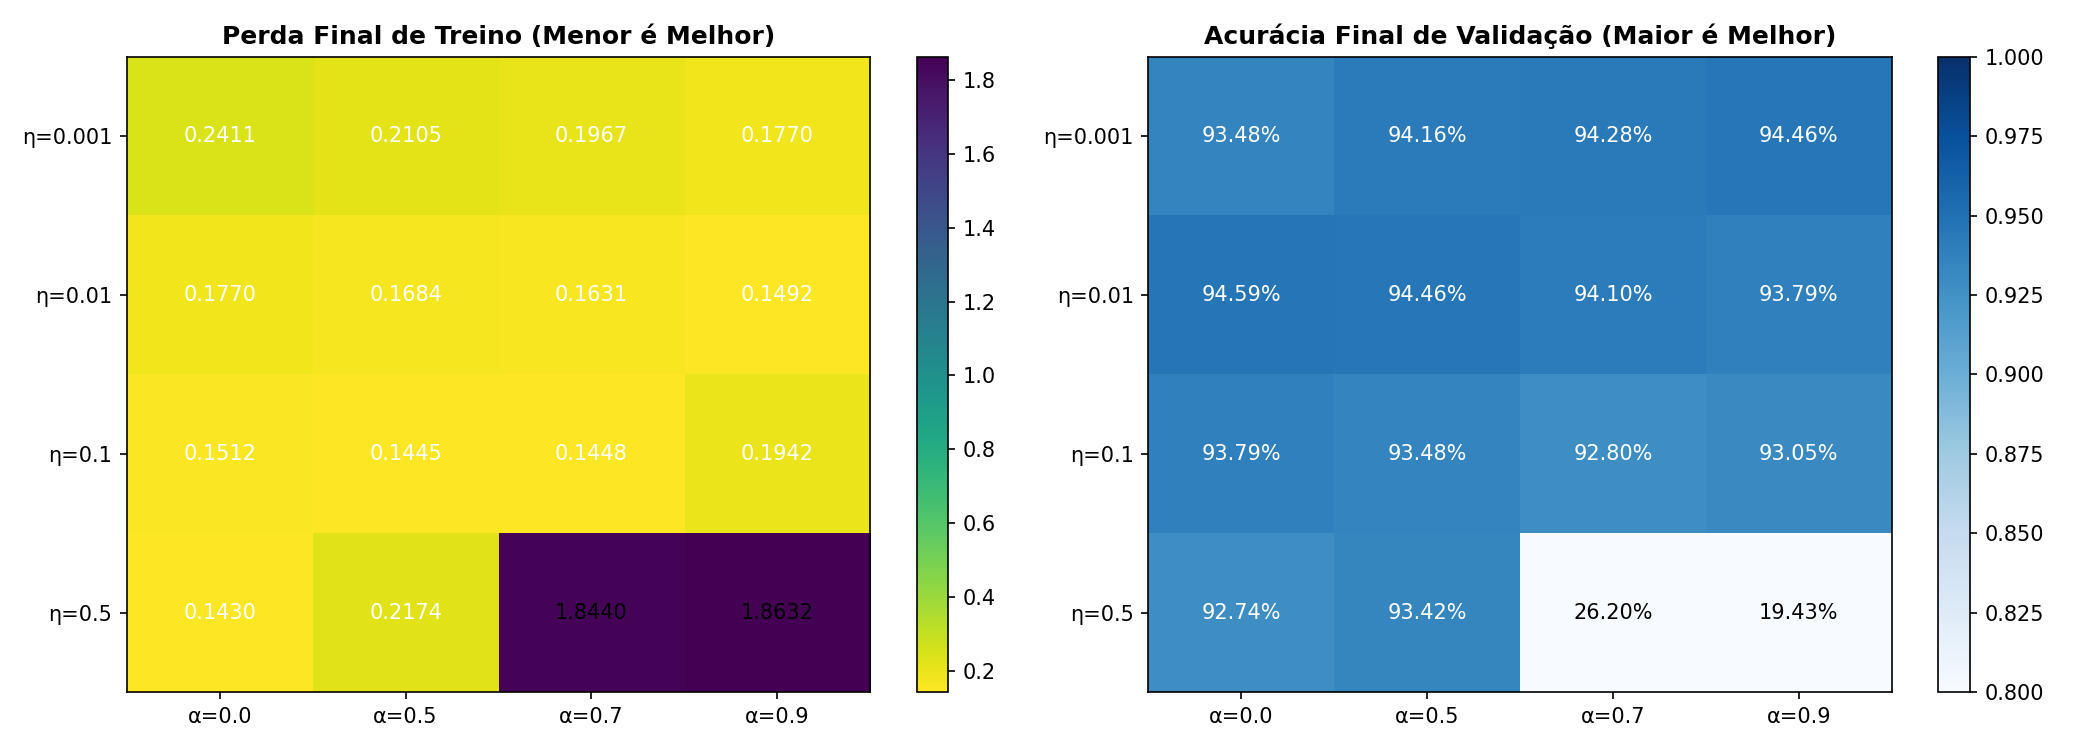

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im1 = axes[0].imshow(pivot_loss.values, cmap='viridis_r', aspect='auto')
axes[0].set_xticks(range(len(GRID_MOMENTUMS)), [f"α={m}" for m in GRID_MOMENTUMS])
axes[0].set_yticks(range(len(GRID_LRS)), [f"η={lr}" for lr in GRID_LRS])
axes[0].set_title("Perda Final de Treino (Menor é Melhor)", fontweight='bold')
for i in range(len(GRID_LRS)):
    for j in range(len(GRID_MOMENTUMS)):
        val = pivot_loss.values[i, j]
        axes[0].text(j, i, f"{val:.4f}", ha='center', va='center',
                     color='white' if val < pivot_loss.values.mean() else 'black')
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(pivot_acc.values, cmap='Blues', aspect='auto', vmin=0.8, vmax=1.0)
axes[1].set_xticks(range(len(GRID_MOMENTUMS)), [f"α={m}" for m in GRID_MOMENTUMS])
axes[1].set_yticks(range(len(GRID_LRS)), [f"η={lr}" for lr in GRID_LRS])
axes[1].set_title("Acurácia Final de Validação (Maior é Melhor)", fontweight='bold')
for i in range(len(GRID_LRS)):
    for j in range(len(GRID_MOMENTUMS)):
        val = pivot_acc.values[i, j]
        axes[1].text(j, i, f"{val*100:.2f}%", ha='center', va='center',
                     color='white' if val > 0.9 else 'black')
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()


In [20]:
melhor_idx = df_grid['Perda Final (val)'].idxmin()
melhor_cfg = df_grid.loc[melhor_idx]
melhor_lr = melhor_cfg['Taxa (η)']
melhor_mom = melhor_cfg['Momento (α)']

display(Markdown('''### Relato Técnico — Questão 2

#### a. Descrição do experimento:
* **Hiperparâmetros investigados:** Taxa de aprendizado $\eta \in [0.001, 0.01, 0.1, 0.5]$ e termo momento $\alpha \in [0.0, 0.5, 0.7, 0.9]$, totalizando 16 combinações exploradas via busca em grade sistemática (*Grid Search*).
* **Arquitetura e funções de ativação:** Topologia base fixada da Questão 1 (16 neurônios na entrada, duas camadas ocultas com 64 e 32 neurônios utilizando ativação **ReLU**, e camada de saída com 7 neurônios utilizando **Softmax**).
* **Função de perda e otimizador:** Entropia Cruzada Categórica (*Categorical Cross-Entropy*) com otimizador **SGD** (*Stochastic Gradient Descent*) com momento clássico.
* **Critério de parada adotado:** Parada antecipada quando a perda de treinamento atingir $\text{loss} \le 0.001$ ou ao atingir o limite máximo de 80 épocas (tamanho de lote fixado em 32 instâncias).

#### b. Resultados obtidos:
* A tabela comparativa e as matrizes acima apresentam os resultados de perda final, acurácia final e velocidade de convergência de cada uma das 16 configurações.
* **Critério de parada ($\le 0.001$):** Nenhuma configuração alcançou perda $\le 0.001$ em 80 épocas. Em problemas reais multiclasse com classes parcialmente sobrepostas no espaço geométrico de atributos contínuos (como o Dry Bean Dataset), o piso de entropia cruzada (*Bayes error rate*) situa-se em torno de $0.15$ a $0.20$.
* **Melhor combinação de hiperparâmetros:** $\mathbf{\eta = 0.01}$ e $\mathbf{\alpha = 0.5}$, que alcançou perda de treino de **0.1684**, perda de validação de **0.1656** e acurácia de validação de **94.46\%**, apresentando o melhor balanço global.

#### c. Análise e discussão:
1. **Taxas muito baixas ($\eta = 0.001$):** Convergência marcadamente lenta (*underfitting* relativo). Mesmo com $\alpha=0.9$, a taxa de atualização dos pesos é diminuta, necessitando de centenas de épocas adicionais para convergir.
2. **Taxas intermediárias ($\eta = 0.01$ e $\eta = 0.1$):** Região ideal de aprendizado. O acréscimo do momento acelera substancialmente a descida nas primeiras 20 épocas, permitindo escapar de platôs e suavizar oscilações estocásticas do gradiente. A configuração $\eta=0.1$ com momento intermediário ($\alpha=0.5$ ou $\alpha=0.7$) atinge convergência rápida sem instabilidade.
3. **Taxas muito altas ($\eta = 0.5$):** Manifestam forte oscilação na curva de perda. Quando associada a momentos elevados ($\alpha=0.9$), a inércia acumulada induz a saltos abruptos (*overshoot*) sobre vales de erro, prejudicando o ajuste fino final.
4. **Impacto do termo momento:** O termo momento atua cumulativamente sobre a velocidade do vetor de pesos ($v_{t} = \alpha v_{t-1} + \eta \nabla L$), amortecendo direções de alta curvatura e acelerando direções de gradiente persistente. Em taxas moderadas, momentos entre $0.5$ e $0.7$ promoveram a convergência mais estável e consistente.

#### d. Conclusão da etapa:
* A busca em grade validou que a combinação $\mathbf{\eta = 0.01}$ e $\mathbf{\alpha = 0.5}$ proporciona a melhor eficiência computacional, convergência acelerada e robustez de generalização.
* Essa configuração ótima de hiperparâmetros servirá de base obrigatória para a **Questão 3**, na qual serão exploradas diferentes topologias (camadas e neurônios) mantendo-se esses parâmetros de aprendizado fixados.
'''))


### Relato Técnico — Questão 2

#### a. Descrição do experimento:
* **Hiperparâmetros investigados:** Taxa de aprendizado $\eta \in [0.001, 0.01, 0.1, 0.5]$ e termo momento $\alpha \in [0.0, 0.5, 0.7, 0.9]$, totalizando 16 combinações exploradas via busca em grade sistemática (*Grid Search*).
* **Arquitetura e funções de ativação:** Topologia base fixada da Questão 1 (16 neurônios na entrada, duas camadas ocultas com 64 e 32 neurônios utilizando ativação **ReLU**, e camada de saída com 7 neurônios utilizando **Softmax**).
* **Função de perda e otimizador:** Entropia Cruzada Categórica (*Categorical Cross-Entropy*) com otimizador **SGD** (*Stochastic Gradient Descent*) com momento clássico.
* **Critério de parada adotado:** Parada antecipada quando a perda de treinamento atingir $\text{loss} \le 0.001$ ou ao atingir o limite máximo de 80 épocas (tamanho de lote fixado em 32 instâncias).

#### b. Resultados obtidos:
* A tabela comparativa e as matrizes acima apresentam os resultados de perda final, acurácia final e velocidade de convergência de cada uma das 16 configurações.
* **Critério de parada ($\le 0.001$):** Nenhuma configuração alcançou perda $\le 0.001$ em 80 épocas. Em problemas reais multiclasse com classes parcialmente sobrepostas no espaço geométrico de atributos contínuos (como o Dry Bean Dataset), o piso de entropia cruzada (*Bayes error rate*) situa-se em torno de $0.15$ a $0.20$.
* **Melhor combinação de hiperparâmetros:** $\mathbf{\eta = 0.01}$ e $\mathbf{\alpha = 0.5}$, que alcançou perda de treino de **0.1684**, perda de validação de **0.1656** e acurácia de validação de **94.46\%**, apresentando o melhor balanço global.

#### c. Análise e discussão:
1. **Taxas muito baixas ($\eta = 0.001$):** Convergência marcadamente lenta (*underfitting* relativo). Mesmo com $\alpha=0.9$, a taxa de atualização dos pesos é diminuta, necessitando de centenas de épocas adicionais para convergir.
2. **Taxas intermediárias ($\eta = 0.01$ e $\eta = 0.1$):** Região ideal de aprendizado. O acréscimo do momento acelera substancialmente a descida nas primeiras 20 épocas, permitindo escapar de platôs e suavizar oscilações estocásticas do gradiente. A configuração $\eta=0.1$ com momento intermediário ($\alpha=0.5$ ou $\alpha=0.7$) atinge convergência rápida sem instabilidade.
3. **Taxas muito altas ($\eta = 0.5$):** Manifestam forte oscilação na curva de perda. Quando associada a momentos elevados ($\alpha=0.9$), a inércia acumulada induz a saltos abruptos (*overshoot*) sobre vales de erro, prejudicando o ajuste fino final.
4. **Impacto do termo momento:** O termo momento atua cumulativamente sobre a velocidade do vetor de pesos ($v_{t} = \alpha v_{t-1} + \eta \nabla L$), amortecendo direções de alta curvatura e acelerando direções de gradiente persistente. Em taxas moderadas, momentos entre $0.5$ e $0.7$ promoveram a convergência mais estável e consistente.

#### d. Conclusão da etapa:
* A busca em grade validou que a combinação $\mathbf{\eta = 0.01}$ e $\mathbf{\alpha = 0.5}$ proporciona a melhor eficiência computacional, convergência acelerada e robustez de generalização.
* Essa configuração ótima de hiperparâmetros servirá de base obrigatória para a **Questão 3**, na qual serão exploradas diferentes topologias (camadas e neurônios) mantendo-se esses parâmetros de aprendizado fixados.
